In [1]:
import pandas as pd
import datetime

import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.arima.model import ARIMA

import warnings
warnings.filterwarnings("ignore")

In [2]:
df_raw = pd.read_csv("eirgrid_ALL_2014_2026.csv")

In [3]:
df_raw.head(5)

,EffectiveTime,SYSTEM_DEMAND,GEN_EXP,WIND_ACTUAL,CO2_INTENSITY,CO2_EMISSIONS,solar_actual,solar_forecast,INTER_EWIC,INTER_MOYLE,INTER_NET,INTER_GRNLK
0,2014-01-01 00:00:00,3758.0,3390.0,1386.0,383.0,1346.0,NaN,NaN,NaN,NaN,NaN,NaN
1,2014-01-01 00:15:00,3724.0,3359.0,1348.0,383.0,1335.0,NaN,NaN,NaN,NaN,NaN,NaN
2,2014-01-01 00:30:00,3666.0,3301.0,1272.0,383.0,1314.0,NaN,NaN,NaN,NaN,NaN,NaN
3,2014-01-01 00:45:00,3611.0,3246.0,1273.0,391.0,1320.0,NaN,NaN,NaN,NaN,NaN,NaN
4,2014-01-01 01:00:00,3543.0,3178.0,1236.0,393.0,1298.0,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
df_selected = df_raw.drop(columns=['CO2_EMISSIONS', 'solar_actual',	'solar_forecast',	'INTER_EWIC',	'INTER_MOYLE',	'INTER_NET',	'INTER_GRNLK'])
df_selected.head(5)

,EffectiveTime,SYSTEM_DEMAND,GEN_EXP,WIND_ACTUAL,CO2_INTENSITY
0,2014-01-01 00:00:00,3758.0,3390.0,1386.0,383.0
1,2014-01-01 00:15:00,3724.0,3359.0,1348.0,383.0
2,2014-01-01 00:30:00,3666.0,3301.0,1272.0,383.0
3,2014-01-01 00:45:00,3611.0,3246.0,1273.0,391.0
4,2014-01-01 01:00:00,3543.0,3178.0,1236.0,393.0


In [6]:

df_selected.index = pd.to_datetime(df_selected["EffectiveTime"], format="%Y-%m-%d %H:%M:%S")


In [7]:
df_selected.head()

,EffectiveTime,SYSTEM_DEMAND,GEN_EXP,WIND_ACTUAL,CO2_INTENSITY
EffectiveTime,,,,,
2014-01-01 00:00:00,2014-01-01 00:00:00,3758.0,3390.0,1386.0,383.0
2014-01-01 00:15:00,2014-01-01 00:15:00,3724.0,3359.0,1348.0,383.0
2014-01-01 00:30:00,2014-01-01 00:30:00,3666.0,3301.0,1272.0,383.0
2014-01-01 00:45:00,2014-01-01 00:45:00,3611.0,3246.0,1273.0,391.0
2014-01-01 01:00:00,2014-01-01 01:00:00,3543.0,3178.0,1236.0,393.0


In [8]:
# Celda 29 adaptada: borrar la columna original
del df_selected["EffectiveTime"]

df_selected.head()

,SYSTEM_DEMAND,GEN_EXP,WIND_ACTUAL,CO2_INTENSITY
EffectiveTime,,,,
2014-01-01 00:00:00,3758.0,3390.0,1386.0,383.0
2014-01-01 00:15:00,3724.0,3359.0,1348.0,383.0
2014-01-01 00:30:00,3666.0,3301.0,1272.0,383.0
2014-01-01 00:45:00,3611.0,3246.0,1273.0,391.0
2014-01-01 01:00:00,3543.0,3178.0,1236.0,393.0


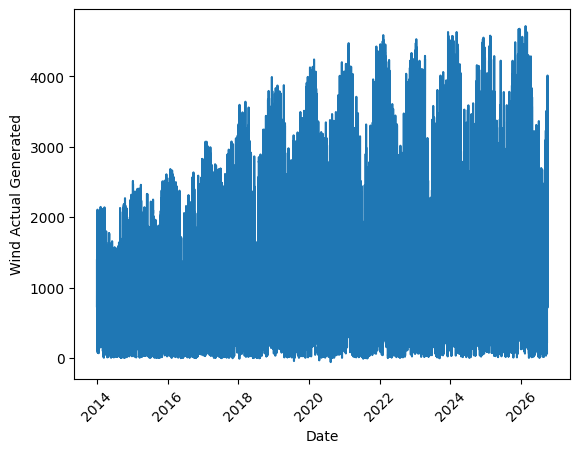

In [9]:
plt.ylabel("Wind Actual Generated")
plt.xlabel("Date")
plt.xticks(rotation=45)
plt.plot(df_selected.index, df_selected["WIND_ACTUAL"])
plt.show()

In [10]:
train=df_selected[df_selected.index < pd.to_datetime("2025-06-01 00:00:00", format="%Y-%m-%d %H:%M:%S")]
test=df_selected[df_selected.index >= pd.to_datetime("2025-06-01 00:00:00", format="%Y-%m-%d %H:%M:%S")]

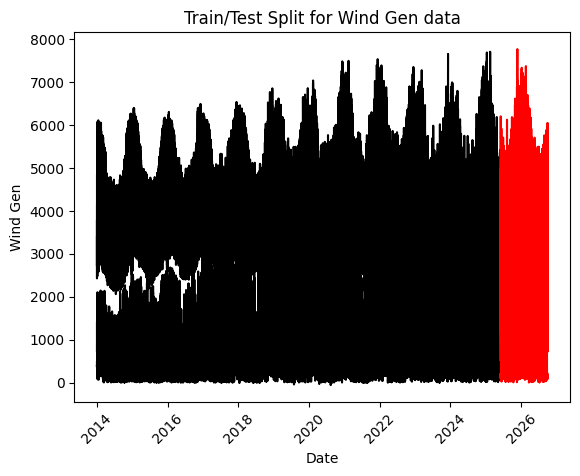

In [11]:
plt.plot(train, color="black", label="Training")
plt.plot(test, color="red", label="Testing")
plt.ylabel("Wind Gen")
plt.xlabel("Date")
plt.xticks(rotation=45)
plt.title("Train/Test Split for Wind Gen data")
plt.show()

In [13]:
y=train["WIND_ACTUAL"]

In [14]:
SARIMAXmodel = SARIMAX(y, order=(2,2,2), seasonal_order=(2,2,2,12))
SARIMAXmodel = SARIMAXmodel.fit()

y_pred = SARIMAXmodel.get_forecast(len(test.index))
y_pred_df=y_pred.conf_int(alpha=0.05)
y_pred_df["Predictions"]= SARIMAXmodel.predict(start=y_pred_df.index[0],
                                           end=y_pred_df.index[-1])
y_pred_df.index=test.index
y_pred_outSARIMAX = y_pred_df["Predictions"]

 This problem is unconstrained.


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            9     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  5.88833D+00    |proj g|=  1.58321D-01

At iterate    5    f=  5.80097D+00    |proj g|=  8.37106D-03

At iterate   10    f=  5.73308D+00    |proj g|=  5.06361D-02


KeyboardInterrupt: 